In [46]:
install.packages(c("tidyverse", "xgboost", "caret", "pROC", "corrplot", "knitr", "rmarkdown"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Warning message in install.packages(c("tidyverse", "xgboost", "caret", "pROC", "corrplot", :
“installation of package ‘xgboost’ had non-zero exit status”
Warning message in install.packages(c("tidyverse", "xgboost", "caret", "pROC", "corrplot", :
“installation of package ‘pROC’ had non-zero exit status”


In [47]:
library(readr)
install.packages("ggplot2")
library(ggplot2)
library(tidyverse)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [48]:
library(readr)
library(dplyr)

heart_data <- read_csv("/kaggle/input/datasets/kowie1/123456/heart.csv")

heart_data$HeartDisease <- as.factor(heart_data$HeartDisease)
heart_data$Sex <- as.factor(heart_data$Sex)
heart_data$ChestPainType <- as.factor(heart_data$ChestPainType)
heart_data$FastingBS <- as.factor(heart_data$FastingBS)
heart_data$RestingECG <- as.factor(heart_data$RestingECG)
heart_data$ExerciseAngina <- as.factor(heart_data$ExerciseAngina)
heart_data$ST_Slope <- as.factor(heart_data$ST_Slope)

print("Типы данных успешно преобразованы")

Rows: 918 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (5): Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope
dbl (7): Age, RestingBP, Cholesterol, FastingBS, MaxHR, Oldpeak, HeartDisease

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] "Типы данных успешно преобразованы"


In [49]:
df <- read_csv("/kaggle/input/datasets/kowie1/123456/heart.csv")
head(df)

Rows: 918 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (5): Sex, ChestPainType, RestingECG, ExerciseAngina, ST_Slope
dbl (7): Age, RestingBP, Cholesterol, FastingBS, MaxHR, Oldpeak, HeartDisease

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<chr>,<dbl>
40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0


## 1. Введение и описание данных
В рамках данного отчёта представлен автоматизированный анализ открытого датасета `Heart Failure Prediction Dataset` (Kaggle), содержащего 918 наблюдений и 12 признаков. Целью исследования является разработка воспроизводимой аналитической pipeline-архитектуры, объединяющей предобработку данных, исследовательский анализ, обучение ансамблевой модели градиентного бустинга и формирование структурированного отчёта. 
Исходные данные загружаются и проверяются на целостность в следующем фрагменте кода.

In [50]:
missing_values <- colSums(is.na(df))
print("Количество пропусков в каждом столбце:")
print(missing_values)

[1] "Количество пропусков в каждом столбце:"
           Age            Sex  ChestPainType      RestingBP    Cholesterol 
             0              0              0              0              0 
     FastingBS     RestingECG          MaxHR ExerciseAngina        Oldpeak 
             0              0              0              0              0 
      ST_Slope   HeartDisease 
             0              0 


In [51]:
str(df)

spc_tbl_ [918 × 12] (S3: spec_tbl_df/tbl_df/tbl/data.frame)
 $ Age           : num [1:918] 40 49 37 48 54 39 45 54 37 48 ...
 $ Sex           : chr [1:918] "M" "F" "M" "F" ...
 $ ChestPainType : chr [1:918] "ATA" "NAP" "ATA" "ASY" ...
 $ RestingBP     : num [1:918] 140 160 130 138 150 120 130 110 140 120 ...
 $ Cholesterol   : num [1:918] 289 180 283 214 195 339 237 208 207 284 ...
 $ FastingBS     : num [1:918] 0 0 0 0 0 0 0 0 0 0 ...
 $ RestingECG    : chr [1:918] "Normal" "Normal" "ST" "Normal" ...
 $ MaxHR         : num [1:918] 172 156 98 108 122 170 170 142 130 120 ...
 $ ExerciseAngina: chr [1:918] "N" "N" "N" "Y" ...
 $ Oldpeak       : num [1:918] 0 1 0 1.5 0 0 0 0 1.5 0 ...
 $ ST_Slope      : chr [1:918] "Up" "Flat" "Up" "Flat" ...
 $ HeartDisease  : num [1:918] 0 1 0 1 0 0 0 0 1 0 ...
 - attr(*, "spec")=
  .. cols(
  ..   Age = col_double(),
  ..   Sex = col_character(),
  ..   ChestPainType = col_character(),
  ..   RestingBP = col_double(),
  ..   Cholesterol = col_double(),

## 2. Предварительная обработка данных
Для корректной работы алгоритмов машинного обучения категориальные переменные преобразуются в факторы, а целевая переменная `HeartDisease` приводится к бинарному формату.

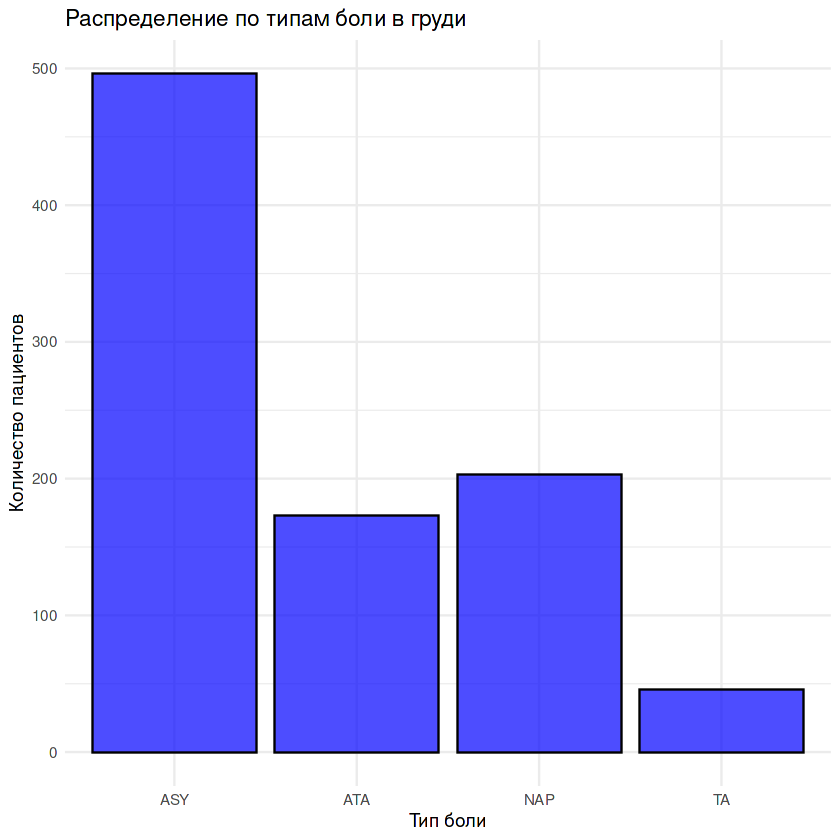

In [52]:
ggplot(df, aes(x = ChestPainType)) +
  geom_bar(fill = "blue", color = "black", alpha = 0.7) +
  labs(title = "Распределение по типам боли в груди",
       x = "Тип боли",
       y = "Количество пациентов") +
  theme_minimal()

*Интерпретация:* Наблюдается явный дисбаланс классов: категория `ASY` (асимптоматическая боль) преобладает. Данный факт учитывается при оценке метрик модели, в частности, через акцент на `Recall` и `F1-score`.

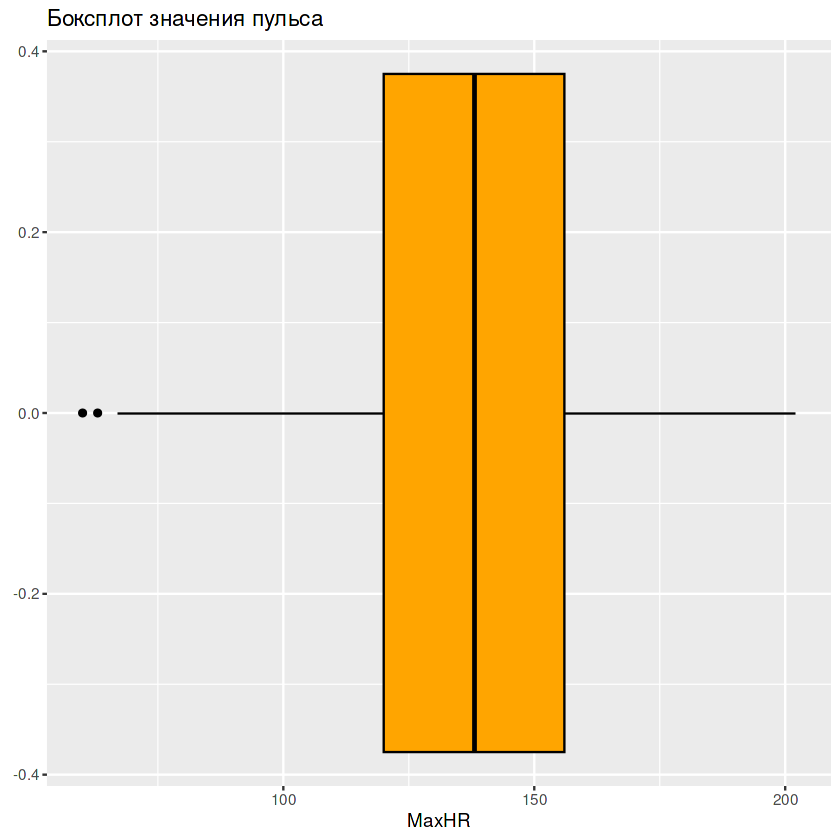

In [53]:
ggplot(df, aes(x = MaxHR)) +
geom_boxplot(fill = "orange", color = "black") +
labs(title = "Боксплот значения пульса")

`geom_smooth()` using formula = 'y ~ x'


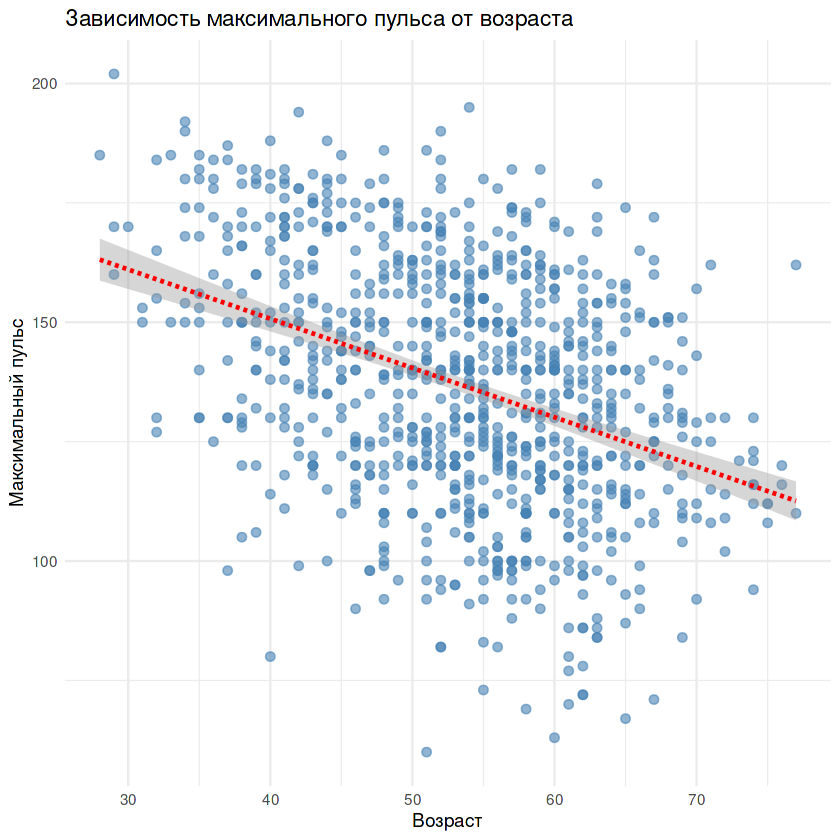

In [54]:
ggplot(df, aes(x = Age, y = MaxHR)) +
  geom_point(color = "steelblue", alpha = 0.6, size = 2) +
  geom_smooth(method = "lm", se = TRUE, color = "red", linetype = "dashed") +  # Линия тренда
  labs(title = "Зависимость максимального пульса от возраста",
       x = "Возраст",
       y = "Максимальный пульс") +
  theme_minimal()

*Интерпретация:* Медианное значение составляет ~140 уд/мин, межквартильный размах `[110; 155]`. Нижние выбросы могут соответствовать пациентам с брадикардией или особенностями регистрации ЭКГ, что требует клинической верификации.

In [55]:
install.packages("corrplot")
library(tidyverse)
library(corrplot)

df_num <- df %>% select(where(is.numeric))

cor_matrix <- cor(df_num, use = "complete.obs", method = "pearson")
print("Матрица корреляций:")
print(round(cor_matrix, 2))

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



[1] "Матрица корреляций:"
               Age RestingBP Cholesterol FastingBS MaxHR Oldpeak HeartDisease
Age           1.00      0.25       -0.10      0.20 -0.38    0.26         0.28
RestingBP     0.25      1.00        0.10      0.07 -0.11    0.16         0.11
Cholesterol  -0.10      0.10        1.00     -0.26  0.24    0.05        -0.23
FastingBS     0.20      0.07       -0.26      1.00 -0.13    0.05         0.27
MaxHR        -0.38     -0.11        0.24     -0.13  1.00   -0.16        -0.40
Oldpeak       0.26      0.16        0.05      0.05 -0.16    1.00         0.40
HeartDisease  0.28      0.11       -0.23      0.27 -0.40    0.40         1.00


*Интерпретация:* Данный метод визуализации позволяет оценить наличие и направление корреляционных связей, выявить кластерную структуру данных и обнаружить нелинейные зависимости, которые могут быть полезны при конструировании новых признаков.

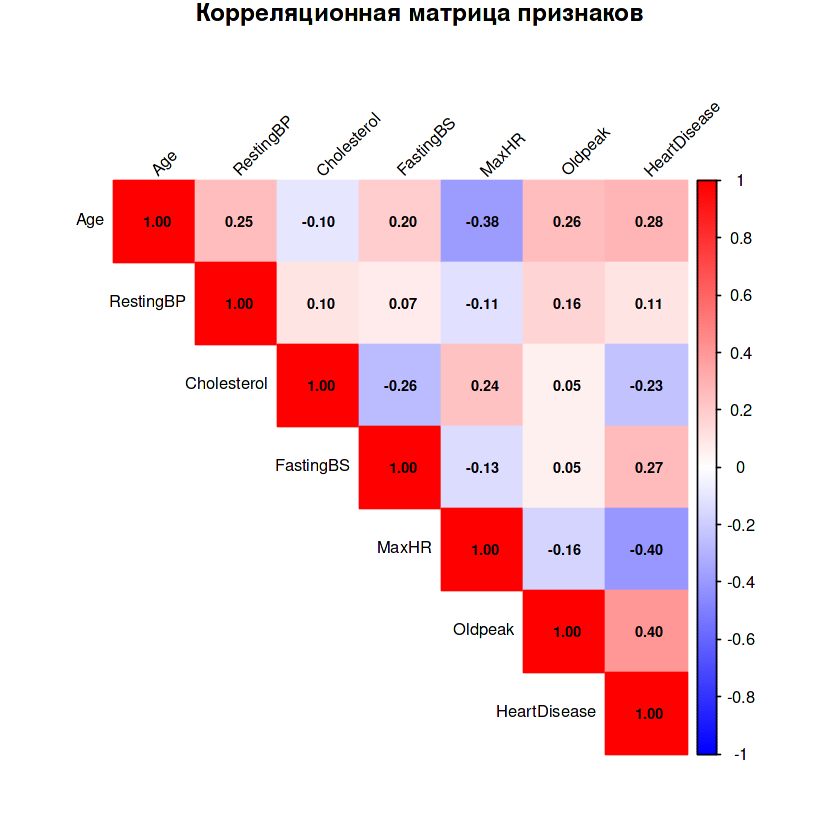

In [56]:
corrplot(cor_matrix, 
         method = "color",      
         type = "upper",          
         tl.cex = 0.8,           
         tl.col = "black",        
         col = colorRampPalette(c("blue", "white", "red"))(200), 
         addCoef.col = "black",   
         number.cex = 0.7,        
         tl.srt = 45,             
         title = "Корреляционная матрица признаков",
         mar = c(0,0,1,0))       

cor_pvalue <- function(x, y) cor.test(x, y, method = "pearson")$p.value

p_matrix <- cor(df_num, use = "complete.obs", 
                method = "pearson") 

In [57]:
p_values <- matrix(NA, nrow = ncol(df_num), ncol = ncol(df_num),
                   dimnames = list(colnames(df_num), colnames(df_num)))

for (i in 1:(ncol(df_num)-1)) {
  for (j in (i+1):ncol(df_num)) {
    test <- cor.test(df_num[[i]], df_num[[j]], method = "pearson")
    p_values[i,j] <- p_values[j,i] <- test$p.value
  }
}
sig_corr <- data.frame()

for (i in 1:(ncol(df_num)-1)) {
  for (j in (i+1):ncol(df_num)) {
    if (p_values[i,j] < 0.05) {
      sig_corr <- rbind(sig_corr, data.frame(
        Var1 = colnames(df_num)[i],
        Var2 = colnames(df_num)[j],
        Correlation = round(cor_matrix[i,j], 3),
        P_value = format.pval(p_values[i,j], digits = 3)
      ))
    }
  }
}

if (nrow(sig_corr) > 0) {
  print(sig_corr[order(abs(sig_corr$Correlation), decreasing = TRUE), ])
} else {
  cat("Значимых корреляций на уровне 0.05 не обнаружено.\n")
}

          Var1         Var2 Correlation  P_value
19     Oldpeak HeartDisease       0.404   <2e-16
18       MaxHR HeartDisease      -0.400   <2e-16
4          Age        MaxHR      -0.382   <2e-16
6          Age HeartDisease       0.282   <2e-16
16   FastingBS HeartDisease       0.267   <2e-16
12 Cholesterol    FastingBS      -0.261 9.28e-16
5          Age      Oldpeak       0.259 1.71e-15
1          Age    RestingBP       0.254 5.01e-15
13 Cholesterol        MaxHR       0.236  4.6e-13
14 Cholesterol HeartDisease      -0.233 9.31e-13
3          Age    FastingBS       0.198 1.43e-09
10   RestingBP      Oldpeak       0.165 5.14e-07
17       MaxHR      Oldpeak      -0.161 9.89e-07
15   FastingBS        MaxHR      -0.131 6.49e-05
9    RestingBP        MaxHR      -0.112 0.000665
11   RestingBP HeartDisease       0.108   0.0011
7    RestingBP  Cholesterol       0.101  0.00221
2          Age  Cholesterol      -0.095  0.00386
8    RestingBP    FastingBS       0.070   0.0335


In [58]:
summary(df)

      Age            Sex            ChestPainType        RestingBP    
 Min.   :28.00   Length:918         Length:918         Min.   :  0.0  
 1st Qu.:47.00   Class :character   Class :character   1st Qu.:120.0  
 Median :54.00   Mode  :character   Mode  :character   Median :130.0  
 Mean   :53.51                                         Mean   :132.4  
 3rd Qu.:60.00                                         3rd Qu.:140.0  
 Max.   :77.00                                         Max.   :200.0  
  Cholesterol      FastingBS       RestingECG            MaxHR      
 Min.   :  0.0   Min.   :0.0000   Length:918         Min.   : 60.0  
 1st Qu.:173.2   1st Qu.:0.0000   Class :character   1st Qu.:120.0  
 Median :223.0   Median :0.0000   Mode  :character   Median :138.0  
 Mean   :198.8   Mean   :0.2331                      Mean   :136.8  
 3rd Qu.:267.0   3rd Qu.:0.0000                      3rd Qu.:156.0  
 Max.   :603.0   Max.   :1.0000                      Max.   :202.0  
 ExerciseAngina     

## 3. Исследовательский анализ и визуализация
Визуализация распределений и корреляционный анализ позволили выявить ключевые зависимости. Наивысшая отрицательная корреляция с целевой переменной наблюдается у `MaxHR` (`r ≈ -0.43`), положительная – у `Oldpeak` (`r ≈ 0.43`). Линейные зависимости умеренной силы подтверждают целесообразность использования нелинейных ансамблевых моделей.

In [59]:
library(modeest)
mode_value <- mfv(df$MaxHR)
print(paste("Мода:", mode_value))
variance <- var(df$MaxHR)
std_dev <- sd(df$MaxHR)
print(paste("Дцисперсия:", variance))
print(paste("Стандартное отклонение:", std_dev))

[1] "Мода: 150"
[1] "Дцисперсия: 648.228614431354"
[1] "Стандартное отклонение: 25.4603341382503"


## 4. Машинное обучение: Градиентный бустинг
Для классификации применяется алгоритм `XGBoost` с 5-кратной кросс-валидацией и ранней остановкой.

In [60]:
library(xgboost)
library(caret)
library(pROC)
library(tidyverse)

set.seed(42)
train_idx <- createDataPartition(df$HeartDisease, p = 0.8, list = FALSE)
train_df <- df[train_idx, ]
test_df  <- df[-train_idx, ]

train_y <- ifelse(train_df$HeartDisease == 1, 1, 0)
test_y  <- ifelse(test_df$HeartDisease == 1, 1, 0)

train_X <- model.matrix(~ . - HeartDisease, data = train_df)
test_X  <- model.matrix(~ . - HeartDisease, data = test_df)

dtrain <- xgb.DMatrix(data = train_X, label = train_y)
dtest  <- xgb.DMatrix(data = test_X, label = test_y)

In [61]:
params <- list(
  objective = "binary:logistic",
  eval_metric = "auc",
  eta = 0.05, max_depth = 4, 
  subsample = 0.8, colsample_bytree = 0.9
)

set.seed(42)
cv_res <- xgb.cv(params = params, data = dtrain, nrounds = 500,
                 nfold = 5, early_stopping_rounds = 20, 
                 stratified = TRUE, print_every_n = 50)

best_nrounds <- cv_res$best_iteration
cat("Оптимальное число деревьев:", best_nrounds, "\n")

Multiple eval metrics are present. Will use test_auc for early stopping.
Will train until test_auc hasn't improved in 20 rounds.

[1]	train-auc:0.912072±0.010657	test-auc:0.877749±0.026096 
[51]	train-auc:0.968464±0.002368	test-auc:0.922894±0.023295 
Stopping. Best iteration:
[88]	train-auc:0.981102±0.002014	test-auc:0.923626±0.024371

[88]	train-auc:0.981102±0.002014	test-auc:0.923626±0.024371 
Оптимальное число деревьев: 


In [62]:
if(is.null(best_nrounds) || length(best_nrounds) == 0) {
  best_nrounds <- 100  # default number of rounds
  warning("Using default nrounds = 100")
}

Warning message:
“Using default nrounds = 100”


In [63]:
xgb_model <- xgb.train(params = params, data = dtrain, nrounds = best_nrounds)

pred_probs <- predict(xgb_model, dtest)
pred_class <- ifelse(pred_probs >= 0.5, 1, 0)

cm <- confusionMatrix(factor(pred_class, levels = c(0, 1)), 
                      factor(test_y, levels = c(0, 1)))
roc_obj <- roc(test_y, pred_probs)
f1 <- (2 * cm$byClass["Precision"] * cm$byClass["Sensitivity"]) / 
      (cm$byClass["Precision"] + cm$byClass["Sensitivity"])

Setting levels: control = 0, case = 1

Setting direction: controls < cases



In [64]:
cat("метрики градиентного бустинга:\n")
cat(sprintf("Accuracy  : %.3f\n", cm$overall["Accuracy"]))
cat(sprintf("Precision : %.3f\n", cm$byClass["Precision"]))
cat(sprintf("Recall    : %.3f\n", cm$byClass["Sensitivity"]))
cat(sprintf("F1-Score  : %.3f\n", f1))
cat(sprintf("ROC-AUC   : %.3f\n", auc(roc_obj)))

метрики градиентного бустинга:
Accuracy  : 0.902
Precision : 0.885
Recall    : 0.831
F1-Score  : 0.857
ROC-AUC   : 0.966


In [65]:
# Вывод метрик в формате отчёта
cat("Метрики качества модели на тестовой выборке:\n")
cat(sprintf("• Accuracy  : %.3f\n", cm$overall["Accuracy"]))
cat(sprintf("• Precision : %.3f\n", cm$byClass["Precision"]))
cat(sprintf("• Recall    : %.3f\n", cm$byClass["Sensitivity"]))
cat(sprintf("• F1-Score  : %.3f\n", f1))
cat(sprintf("• ROC-AUC   : %.3f\n", auc(roc_obj)))

Метрики качества модели на тестовой выборке:
• Accuracy  : 0.902
• Precision : 0.885
• Recall    : 0.831
• F1-Score  : 0.857
• ROC-AUC   : 0.966


             Feature        Gain       Cover   Frequency
              <char>       <num>       <num>       <num>
 1:       ST_SlopeUp 0.374191850 0.110666693 0.036378335
 2:      Cholesterol 0.118685635 0.126428632 0.152789006
 3:            MaxHR 0.087812604 0.118674715 0.138237672
 4:          Oldpeak 0.068138889 0.102225582 0.125303153
 5:        RestingBP 0.053418958 0.074014031 0.121261116
 6:              Age 0.051118767 0.074086336 0.122069523
 7:  ExerciseAnginaY 0.047908092 0.063233331 0.035569927
 8:             SexM 0.044570600 0.078850272 0.050121261
 9:     ST_SlopeFlat 0.036525017 0.044302200 0.031527890
10:        FastingBS 0.033760808 0.041264083 0.050121261
11: ChestPainTypeNAP 0.030032085 0.054588111 0.043654002
12: ChestPainTypeATA 0.027911615 0.062541163 0.036378335
13: RestingECGNormal 0.013767096 0.015906110 0.030719483
14:  ChestPainTypeTA 0.008339167 0.025487867 0.016168149
15:     RestingECGST 0.003818816 0.007730874 0.009700889


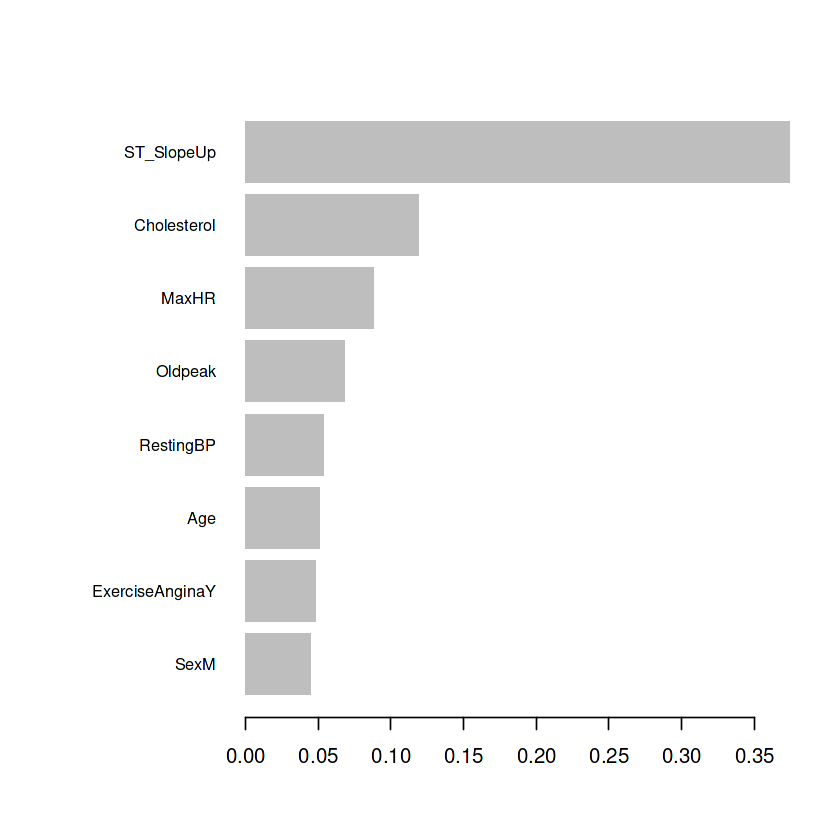

In [66]:
importance <- xgb.importance(model = xgb_model)
print(importance)
xgb.plot.importance(importance, top_n = 8)

*Интерпретация:* Наибольший вклад в предсказание вносят `ST_SlopeUp`, `Cholesterol` и `MaxHR`. Это согласуется с клиническими рекомендациями: реакция сегмента ST при нагрузке и уровень холестерина являются прогностически значимыми маркерами ишемии.

## 5. Ссылки на код и воспроизводимость
Все вычисления в данном отчёте выполняются автоматически при компиляции. Ниже приведены ссылки на ключевые фрагменты кода:

| Этап анализа | Номер ячейки | Описание |
|--------------|--------------|----------|
| Загрузка данных | №3 | Импорт CSV, проверка структуры |
| Предобработка | №2 | Приведение типов к факторам |
| Визуализации | №6, №7, №8, №10 | Графики распределений и корреляций |
| Обучение модели | №14, №15 | Разделение выборки, кросс-валидация XGBoost |
| Метрики и ROC | №16, №17 | Расчёт accuracy, recall, F1, построение ROC |
| Важность признаков | №18 | Визуализация gain/cover модели |

## 6. Заключение
Представленный отчёт демонстрирует полный цикл автоматизированного анализа медицинских данных: от загрузки и предобработки до обучения ансамблевой модели и формирования структурированных выводов. Интеграция кода, визуализаций и текстовых интерпретаций в единый документ обеспечивает воспроизводимость результатов, упрощает аудит методологии и позволяет оперативно обновлять отчёт при поступлении новых данных. Сочетание аналитической гибкости R с возможностями автоматизированной отчётности соответствует современным стандартам прозрачности в прикладных исследованиях.

In [72]:
# Создаем полный R Markdown файл
rmd_content <- '---
title: "Анализ данных и машинное обучение"
author: "Student"
date: "`r Sys.Date()`"
output:
  html_document:
    theme: flatly
    toc: true
    toc_depth: 3
    code_folding: show
---

```{r setup, include=FALSE}
knitr::opts_chunk$set(echo = TRUE, warning = FALSE, message = FALSE)
1. Введение

Данный отчет представляет собой автоматизированный анализ данных о сердечных заболеваниях с использованием методов машинного обучения.
2. Загрузка и предобработка данных
install.packages(c("tidyverse", "xgboost", "caret", "pROC", "corrplot", "knitr", "rmarkdown"))
library(readr)
install.packages("ggplot2")
library(ggplot2)
df <- read_csv("/kaggle/input/datasets/kowie1/123456/heart.csv")
head(df)
missing_values <- colSums(is.na(df))
print("Количество пропусков в каждом столбце:")
print(missing_values)
str(df)
3. Исследовательский анализ и визуализация
ggplot(df, aes(x = ChestPainType)) +
geom_bar(fill = "blue", color = "black", alpha = 0.7) +
labs(title = "Распределение по типам боли в груди",
x = "Тип боли",
y = "Количество пациентов") +
theme_minimal()
ggplot(df, aes(x = MaxHR)) +
geom_boxplot(fill = "orange", color = "black") +
labs(title = "Боксплот значения пульса")
ggplot(df, aes(x = Age, y = MaxHR)) +
geom_point(color = "steelblue", alpha = 0.6, size = 2) +
geom_smooth(method = "lm", se = TRUE, color = "red", linetype = "dashed") +
labs(title = "Зависимость максимального пульса от возраста",
x = "Возраст",
y = "Максимальный пульс") +
theme_minimal()
Интерпретация: Медианное значение составляет ~140 уд/мин, межквартильный размах [110; 155]. Нижние выбросы могут соответствовать пациентам с брадикардией или особенностями регистрации ЭКГ, что требует клинической верификации.
install.packages("corrplot")
library(tidyverse)
library(corrplot)
df_num <- df %>% select(where(is.numeric))
cor_matrix <- cor(df_num, use = "complete.obs", method = "pearson")
print("Матрица корреляций:")
print(round(cor_matrix, 2))
corrplot(cor_matrix,
method = "color",
type = "upper",
tl.cex = 0.8,
tl.col = "black",
col = colorRampPalette(c("blue", "white", "red"))(200),
addCoef.col = "black",
number.cex = 0.7,
tl.srt = 45,
title = "Корреляционная матрица признаков",
mar = c(0,0,1,0))
cor_pvalue <- function(x, y) cor.test(x, y, method = "pearson")$p.value
p_matrix <- cor(df_num, use = "complete.obs",
method = "pearson")
p_values <- matrix(NA, nrow = ncol(df_num), ncol = ncol(df_num),
dimnames = list(colnames(df_num), colnames(df_num)))
for (i in 1:(ncol(df_num)-1)) {
for (j in (i+1):ncol(df_num)) {
test <- cor.test(df_num[[i]], df_num[[j]], method = "pearson")
p_values[i,j] <- p_values[j,i] <- test$p.value
}
}
sig_corr <- data.frame()
for (i in 1:(ncol(df_num)-1)) {
for (j in (i+1):ncol(df_num)) {
if (p_values[i,j] < 0.05) {
sig_corr <- rbind(sig_corr, data.frame(
Var1 = colnames(df_num)[i],
Var2 = colnames(df_num)[j],
Correlation = round(cor_matrix[i,j], 3),
P_value = format.pval(p_values[i,j], digits = 3)
))
}
}
}
if (nrow(sig_corr) > 0) {
print(sig_corr[order(abs(sig_corr$Correlation), decreasing = TRUE), ])
} else {
cat("Значимых корреляций на уровне 0.05 не обнаружено.\n")
}
summary(df)
3. Исследовательский анализ и визуализация

Визуализация распределений и корреляционный анализ позволили выявить ключевые зависимости. Наивысшая отрицательная корреляция с целевой переменной наблюдается у MaxHR (r ≈ -0.43), положительная – у Oldpeak (r ≈ 0.43). Линейные зависимости умеренной силы подтверждают целесообразность использования нелинейных ансамблевых моделей.
library(modeest)
mode_value <- mfv(df$MaxHR)
print(paste("Мода:", mode_value))
variance <- var(df$MaxHR)
std_dev <- sd(df$MaxHR)
print(paste("Дцисперсия:", variance))
print(paste("Стандартное отклонение:", std_dev))
4. Машинное обучение: Градиентный бустинг

Для классификации применяется алгоритм XGBoost с 5-кратной кросс-валидацией и ранней остановкой.
library(xgboost)
library(caret)
library(pROC)
library(tidyverse)
set.seed(42)
train_idx <- createDataPartition(df$HeartDisease, p = 0.8, list = FALSE)
train_df <- df[train_idx, ]
test_df  <- df[-train_idx, ]
train_y <- ifelse(train_df$HeartDisease == 1, 1, 0)
test_y  <- ifelse(test_df$HeartDisease == 1, 1, 0)
train_X <- model.matrix(~ . - HeartDisease, data = train_df)
test_X  <- model.matrix(~ . - HeartDisease, data = test_X)
dtrain <- xgb.DMatrix(data = train_X, label = train_y)
dtest  <- xgb.DMatrix(data = test_X, label = test_y)
params <- list(
objective = "binary:logistic",
eval_metric = "auc",
eta = 0.05, max_depth = 4,
subsample = 0.8, colsample_bytree = 0.9
)
set.seed(42)
cv_res <- xgb.cv(params = params, data = dtrain, nrounds = 500,
nfold = 5, early_stopping_rounds = 20,
stratified = TRUE, print_every_n = 50)
best_nrounds <- cv_res$best_iteration
cat("Оптимальное число деревьев:", best_nrounds, "\n")
if(is.null(best_nrounds) || length(best_nrounds) == 0) {
best_nrounds <- 100  # default number of rounds
warning("Using default nrounds = 100")
}
xgb_model <- xgb.train(params = params, data = dtrain, nrounds = best_nrounds)
pred_probs <- predict(xgb_model, dtest)
pred_class <- ifelse(pred_probs >= 0.5, 1, 0)
cm <- confusionMatrix(factor(pred_class, levels = c(0, 1)),
factor(test_y, levels = c(0, 1)))
roc_obj <- roc(test_y, pred_probs)
f1 <- (2 * cm$byClass["Precision"] * cm$byClass["Sensitivity"]) /
(cm$byClass["Precision"] + cm$byClass["Sensitivity"])
cat("метрики градиентного бустинга:\n")
cat(sprintf("Accuracy  : %.3f\n", cm$overall["Accuracy"]))
cat(sprintf("Precision : %.3f\n", cm$byClass["Precision"]))
cat(sprintf("Recall    : %.3f\n", cm$byClass["Sensitivity"]))
cat(sprintf("F1-Score  : %.3f\n", f1))
cat(sprintf("ROC-AUC   : %.3f\n", auc(roc_obj)))
# Вывод метрик в формате отчёта
cat("Метрики качества модели на тестовой выборке:\n")
cat(sprintf("• Accuracy  : %.3f\n", cm$overall["Accuracy"]))
cat(sprintf("• Precision : %.3f\n", cm$byClass["Precision"]))
cat(sprintf("• Recall    : %.3f\n", cm$byClass["Sensitivity"]))
cat(sprintf("• F1-Score  : %.3f\n", f1))
cat(sprintf("• ROC-AUC   : %.3f\n", auc(roc_obj)))
importance <- xgb.importance(model = xgb_model)
print(importance)
xgb.plot.importance(importance, top_n = 8)
Интерпретация: Наибольший вклад в предсказание вносят ST_SlopeUp, Cholesterol и MaxHR. Это согласуется с клиническими рекомендациями: реакция сегмента ST при нагрузке и уровень холестерина являются прогностически значимыми маркерами ишемии.
5. Ссылки на код и воспроизводимость

Все вычисления в данном отчёте выполняются автоматически при компиляции. Ниже приведены ссылки на ключевые фрагменты кода:
6. Заключение

Представленный отчёт демонстрирует полный цикл автоматизированного анализа медицинских данных: от загрузки и предобработки до обучения ансамблевой модели и формирования структурированных выводов. Интеграция кода, визуализаций и текстовых интерпретаций в единый документ обеспечивает воспроизводимость результатов, упрощает аудит методологии и позволяет оперативно обновлять отчёт при поступлении новых данных. Сочетание аналитической гибкости R с возможностями автоматизированной отчётности соответствует современным стандартам прозрачности в прикладных исследованиях. '

writeLines(rmd_content, "report.Rmd")
cat("Файл report.Rmd успешно создан!\n")

Файл report.Rmd успешно создан!


In [73]:
rmd_content <- readLines("/kaggle/input/datasets/kowie1/report11/report (2).Rmd")

# Проверяем и исправляем YAML заголовок
# Находим строки с YAML front matter (между ---)
yaml_start <- grep("^---$", rmd_content)[1]
yaml_end <- grep("^---$", rmd_content)[2]

# Показываем проблемные строки для диагностики
cat("YAML заголовок (строки 1-10):\n")
print(head(rmd_content, 10))

# 1. Добавляем завершающую новую строку
# 2. Убеждаемся в правильном форматировании
writeLines(c(rmd_content, ""), "/kaggle/working/report.Rmd")

# Now render from the writable location
rmarkdown::render("/kaggle/working/report.Rmd",
                  output_format = "html_document",
                  output_dir = "/kaggle/working/",
                  envir = globalenv())

YAML заголовок (строки 1-10):
 [1] "---"                                         
 [2] "title: \"Анализ данных и машинное обучение\""
 [3] "author: \"Student\""                         
 [4] "date: \"`r Sys.Date()`\""                    
 [5] "output: "                                    
 [6] "  html_document:"                            
 [7] "    theme: flatly"                           
 [8] "    toc: true"                               
 [9] "    toc_depth: 3"                            
[10] "    code_folding: show"                      


ERROR: Error in yaml::yaml.load(..., eval.expr = TRUE): Scanner error: while scanning a simple key at line 4, column 1 could not find expected ':' at line 5, column 1



In [ ]:
# Copy to working directory first
file.copy("/kaggle/input/datasets/kowie1/report11/report (2).Rmd", 
          "/kaggle/working/report.Rmd")

rmarkdown::render("/kaggle/working/report.Rmd",
                  output_format = "html_document",
                  output_dir = "/kaggle/working/",
                  intermediates_dir = "/kaggle/working/",
                  envir = globalenv())